# Regular tetrahedron: original-method comparisons

Which differences reflect atomic models, scientific operators, input-domain
limits or execution failures? This notebook reads the reviewed original files;
**Run All executes no detector and contacts no server.** It runs independently
of [system.ipynb](system.ipynb) and [dfnd.ipynb](dfnd.ipynb), without replacing
their frozen inputs or outputs. Those notebooks establish the native
1.2 Å percolating / 1.4 Å sealed / 1.7 Å nonresident control.

This is a method-characterization study, not an accuracy leaderboard. Four
dummy carbon balls are outside some tools' intended molecular domain. A
rejected result has **no inferred cavity count**.

In [1]:
import hashlib
import json
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import molsysmt as msm
import numpy as np
from IPython.display import Markdown, display
from pyunitwizard import QuantityRecord

import topomt as tmt
from topomt import pyunitwizard as puw
from topomt.provider_output import ProviderRun

CASE = Path.cwd()
if not (CASE / 'artifacts/comparisons_v1/protocol.json').exists():
    CASE = CASE / 'docs/content/benchlab/synthetic/regular_tetrahedron'
DATA = CASE / 'artifacts/comparisons_v1'

def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def quantity(record, field, unit):
    return QuantityRecord.from_dict(record).to_quantity(field=field, unit=unit)

def value(record, field, unit):
    return np.asarray(puw.get_value(quantity(record, field, unit), to_unit=unit))

def qrecord(data, unit, field):
    return QuantityRecord.from_quantity(puw.quantity(data, unit), field=field).to_dict()

def table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(str(v).replace('|', '/') for v in row) + ' |' for row in rows)
    display(Markdown(text))

protocol = json.loads((DATA / 'protocol.json').read_text())
audit = json.loads((DATA / 'model_audit.json').read_text())
receipt = json.loads((DATA / 'evidence_receipt.json').read_text())
for relative, digest in protocol['preserved_files'].items():
    assert sha(CASE / relative) == digest, relative
for relative, digest in receipt['files'].items():
    assert sha(DATA / relative) == digest, relative
assert sha(DATA / 'model_audit.json') == protocol['model_audit_sha256']
source = CASE / protocol['source_file']
xyz = np.asarray(puw.get_value(msm.get(str(source), coordinates=True), to_unit='angstroms')).reshape(-1, 3)
assert xyz.shape == (4, 3)
display(Markdown('All frozen inputs and original evidence pass checksum verification.'))

All frozen inputs and original evidence pass checksum verification.

## Input and atomic-model audit

The canonical system fixes equal radii **1.7 Å** and edge **5.3 Å**. PDB
export rounds the vertex coordinates and does not encode those atomic radii.
The existing compatibility file changes `HETATM` to `ATOM` only: four `DUM/C`
rows, with atom-name columns `C   `. Every current actual submitted PDB is
audited below; no protein chemistry is inferred from this dummy encoding.

Original pyKVFinder `read_pdb` assigns **1.66 Å** through the generic carbon
fallback. Maintained MOLE's original tunnel-specific C table uses **1.61 Å**
with no override. The [audit](artifacts/comparisons_v1/model_audit.json)
links exact source revisions and dictionary hashes. GHECOM's default Chothia
atom/residue patterns and CAVER's table have not yet been traced to effective
DUM assignments; their radii remain **unknown**, rather than assumed equal.

| Model / method | Atomic radius (Å) | Evidence |
| --- | --- | --- |
| native | 1.7 | explicit_frozen_reference |
| pykvfinder | 1.66 | original_read_pdb |
| mole | 1.61 | pinned_source_default_no_override |
| ghecom | unknown | rule_known_effective_assignment_not_yet_audited |
| caver | unknown | table_known_effective_assignment_not_yet_audited |

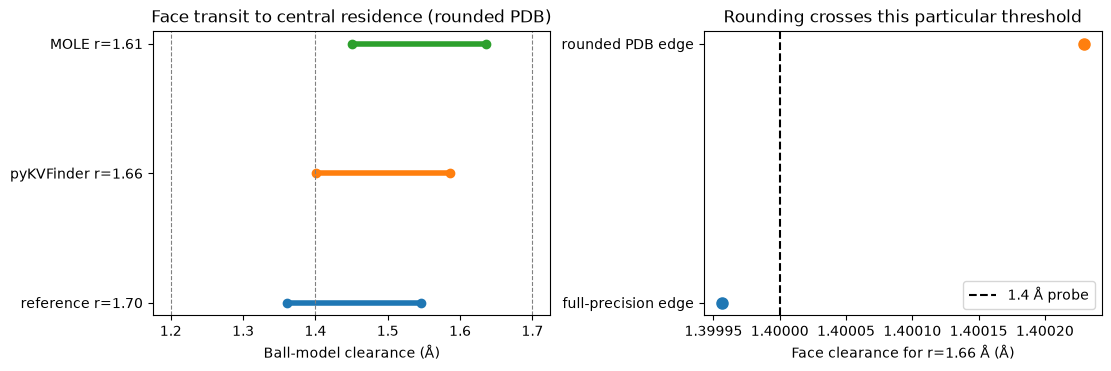

In [2]:
radius_rows = []
for name, entry in audit['radii'].items():
    radius = 'unknown' if entry['radius'] is None else float(value(entry['radius'], 'radius', 'angstroms'))
    radius_rows.append([name, radius, entry['evidence_mode']])
table(['Model / method', 'Atomic radius (Å)', 'Evidence'], radius_rows)

rounded_edge = float(np.linalg.norm(xyz[0] - xyz[1]))
geometric_models = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for index, name in enumerate(('native', 'pykvfinder', 'mole')):
    radius = float(value(audit['radii'][name]['radius'], 'radius', 'angstroms'))
    face = rounded_edge / np.sqrt(3) - radius
    residence = rounded_edge * np.sqrt(6) / 4 - radius
    axes[0].plot([face, residence], [index, index], 'o-', lw=4)
    geometric_models.append({'model': name, 'rounded_pdb_face_clearance': qrecord(face, 'angstroms', 'face_clearance'), 'rounded_pdb_residence_clearance': qrecord(residence, 'angstroms', 'residence_clearance')})
for probe in (1.2, 1.4, 1.7):
    axes[0].axvline(probe, color='grey', lw=.8, ls='--')
axes[0].set(yticks=range(3), yticklabels=['reference r=1.70', 'pyKVFinder r=1.66', 'MOLE r=1.61'], xlabel='Ball-model clearance (Å)', title='Face transit to central residence (rounded PDB)')
for index, edge in enumerate((5.3, rounded_edge)):
    axes[1].plot(edge / np.sqrt(3) - 1.66, index, 'o', markersize=8)
axes[1].axvline(1.4, ls='--', color='black', label='1.4 Å probe')
axes[1].set(yticks=[0, 1], yticklabels=['full-precision edge', 'rounded PDB edge'], xlabel='Face clearance for r=1.66 Å (Å)', title='Rounding crosses this particular threshold')
axes[1].ticklabel_format(axis='x', style='plain', useOffset=False)
axes[1].legend()
plt.show()
assert 5.3 / np.sqrt(3) - 1.66 < 1.4 < rounded_edge / np.sqrt(3) - 1.66

These intervals are independent **atomic-ball model implications**, not
detector predictions. With a 1.66 Å radius, PDB rounding changes the face
clearance from about 1.399956 Å to 1.400229 Å, crossing 1.4 Å. The native
1.7 Å model is safely on the sealed side of that threshold. Matching a
parameter called “probe” does not establish matching operators or geometry.

## Protocol fixed before the observations

The [original protocol](artifacts/comparisons_v1/protocol.json) was committed
before executing these detectors. It declares fourteen rows: each selected
method's standard run and small-system controls. pyKVFinder uses step 0.2 Å,
outer probe 4 Å, zero removal distance and zero volume cutoff in its controls;
GHECOM uses grid 0.4 Å and outer probe 6 Å. Both vary their small probe through
1.2, 1.4 and 1.7 Å. CAVER starts at the origin. Its probe controls stop if the
standard run fails. MOLE's standard and zero-minimum-depth control have no
DFND probe label: MOLE `ProbeRadius` is a different construction parameter.

Each local run used one worker, bounded time/memory and the retained original
engine route. A failed **standard** run stops that method's remaining controls.
No remote calculation was requested. P2Rank was not selected: its learned
protein binding-site prediction is not independent truth for four dummy balls.

In [3]:
observations = {}
accepted = {}
inspected = {}
for folder, filename in [('original_observations', 'protocol.json'), ('positive_cutoff_observations', 'positive_cutoff_protocol.json')]:
    observed = json.loads((DATA / folder / 'observations.json').read_text())
    assert observed['protocol_sha256'] == sha(DATA / filename)
    observations[folder] = observed
    for entry in observed['entries']:
        bundle = entry['original_bundle']
        if bundle is None:
            assert entry['status'] == 'not_executed_after_failure'
            continue
        path = DATA / folder / bundle['file']
        assert sha(path) == bundle['sha256']
        run = ProviderRun.load(path)
        assert run.run_id == bundle['run_id']
        assert hashlib.sha256(run.get_artifact('input/input.pdb')).hexdigest() == protocol['source_sha256']
        assert entry['actual_input']['atom_count'] == 4
        assert entry['actual_input']['atom_name_columns'] == ['C   '] * 4
        inspected[entry['id']] = run
        if entry['status'] == 'completed':
            output = tmt.load_provider_output(path, molecular_system=str(source))
            assert len(output.records) == entry['record_count']
            accepted[entry['id']] = output
        else:
            assert entry['record_counts'] is None
            assert run.metadata['execution_status'] == 'failed'

def outcome_rows(entries):
    return [[entry['id'], entry['status'], entry.get('original_version') or 'see original receipt',
             entry.get('record_count', '—'), entry.get('record_counts') if entry['status'] == 'completed' else 'no accepted output']
            for entry in entries]

table(['Planned run', 'Status', 'Original version', 'Records', 'Original record kinds'], outcome_rows(observations['original_observations']['entries']))

| Planned run | Status | Original version | Records | Original record kinds |
| --- | --- | --- | --- | --- |
| pykvfinder-standard | completed | 0.9.6+uibcdf.2 | 0 | {} |
| pykvfinder-probe-1p2 | execution_failed | 0.9.6+uibcdf.2 | — | no accepted output |
| pykvfinder-probe-1p4 | execution_failed | 0.9.6+uibcdf.2 | — | no accepted output |
| pykvfinder-probe-1p7 | execution_failed | 0.9.6+uibcdf.2 | — | no accepted output |
| ghecom-standard | completed | 2026/08/17 | 0 | {} |
| ghecom-probe-1p2 | completed | 2026/08/17 | 1 | {'pocket': 1} |
| ghecom-probe-1p4 | completed | 2026/08/17 | 0 | {} |
| ghecom-probe-1p7 | completed | 2026/08/17 | 0 | {} |
| caver-standard | execution_failed | 3.02 | — | no accepted output |
| caver-probe-1p2 | not_executed_after_failure | see original receipt | — | no accepted output |
| caver-probe-1p4 | not_executed_after_failure | see original receipt | — | no accepted output |
| caver-probe-1p7 | not_executed_after_failure | see original receipt | — | no accepted output |
| mole-standard | execution_failed | see original receipt | — | no accepted output |
| mole-minimum-depth | not_executed_after_failure | see original receipt | — | no accepted output |

GHECOM 2026/08/17 completes: standard is empty; the 1.2 Å control has one
original P-mode morphological region (263 grid points); the 1.4 and 1.7 Å
controls are empty. These are results of its own operator and input model.
Agreement or disagreement with DFND counts is not an accuracy test here.

pyKVFinder 0.9.6+uibcdf.2 completes empty with original defaults. All three
zero-cutoff controls produce **invalid exported results**, not zero cavities.
The compatibility fork changes packaging, not scientific kernels or data.
These observations establish behaviour for this build/input, not every
upstream release or platform.

CAVER 3.02 logs an origin/shell failure and “Computed tunnels missing” even
though its process exits normally; mandatory profiles are absent. MOLE
2.5.26.10.26 reads four atoms and then fails with a null-reference message.
Neither result supplies a channel or cavity count. Their remaining controls
were not executed after the failed standards. No new shell/origin tuning or
MOLE kernel change is hidden in the comparison.

In [4]:
failure_tokens = {
    'pykvfinder-probe-1p2': ('exceeds the maximum supported', 'Cavity labels may not be unique'),
    'caver-standard': ('Starting point is out', 'Computed tunnels missing'),
    'mole-standard': ('Object reference not set',),
}
diagnostic_lines = []
for identifier, tokens in failure_tokens.items():
    run = inspected[identifier]
    lines = [line.strip() for name, content in run.artifacts if name.endswith('.txt')
             for line in content.decode('utf-8', errors='replace').splitlines()]
    selected = sorted({line for line in lines if any(token in line for token in tokens)})
    assert selected, identifier
    diagnostic_lines.append([identifier, '<br>'.join(selected)])
table(['Failed original run', 'Original diagnostic excerpt'], diagnostic_lines)

| Failed original run | Original diagnostic excerpt |
| --- | --- |
| pykvfinder-probe-1p2 | WARNING:root:The number of cavities (6112) exceeds the maximum supported (1352). Cavity labels may not be unique. |
| caver-standard | WARNING: Starting point is out. Check starting point position ([-6.1536078942028E-4, 9.64055053157739E-5, -3.900553100931461E-5]). If starting point is correct, increase shell_radius or decrease shell_depth.<br>caver.ui.CalculationException: Computed tunnels missing in /tmp/topomt_caver_4muqnk5z/results/data/tunnels, set load_tunnels to 'no'. |
| mole-standard | Object reference not set to an instance of an object. |

## A separately declared post-observation diagnostic

The original pyKVFinder zero-cutoff run warns of **6112** cavity labels,
exceeding its **1352** label capacity. Its exported grid and descriptor label
sets disagree, so TopoMT refuses to expose them as accepted cavities. In the
pinned original C source, `DFS` returns at grid boundaries while `_cluster`
increments the label and tests accumulated volume against the cutoff. A
zero-volume cluster is therefore a plausible source of the label inflation.

Before further execution, the [diagnostic protocol](artifacts/comparisons_v1/positive_cutoff_protocol.json)
was committed with one change: minimum volume becomes one voxel,
**(0.2 Å)³ = 0.008 Å³**. This is a post-observation hypothesis test, not a
revision of the failed predeclared controls. It completes with one region
at each probe. This supports the cutoff-dependence diagnosis; it does not
prove the entire original clustering implementation correct.

| Diagnostic run | Status | Original version | Records | Original kinds |
| --- | --- | --- | --- | --- |
| pykvfinder-one-voxel-1p2 | completed | 0.9.6+uibcdf.2 | 1 | {'cavity': 1} |
| pykvfinder-one-voxel-1p4 | completed | 0.9.6+uibcdf.2 | 1 | {'cavity': 1} |
| pykvfinder-one-voxel-1p7 | completed | 0.9.6+uibcdf.2 | 1 | {'cavity': 1} |

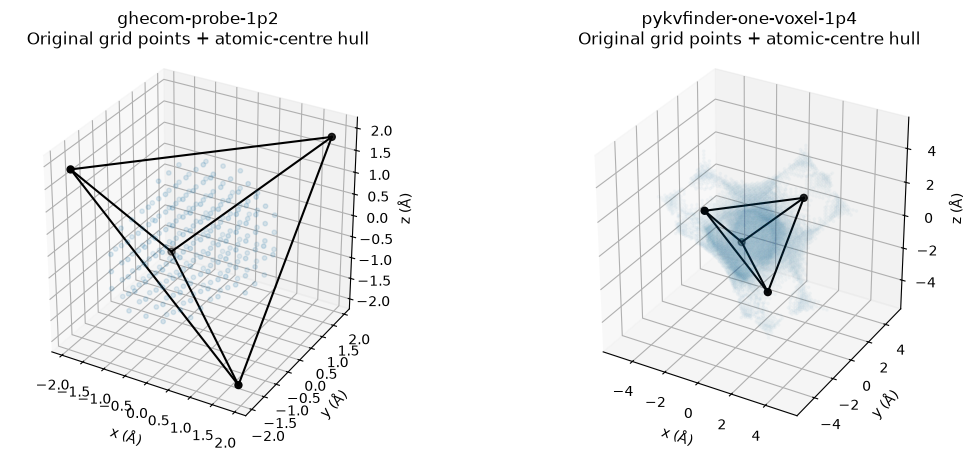

| Original region | Grid points | Inside centre hull |
| --- | --- | --- |
| ghecom-probe-1p2 | 263 | 184 |
| pykvfinder-one-voxel-1p4 | 9136 | 1561 |

In [5]:
diagnostic = json.loads((DATA / 'positive_cutoff_protocol.json').read_text())
assert diagnostic['frozen_before_original_topography'] is False
assert diagnostic['declared_before_diagnostic_execution'] is True
table(['Diagnostic run', 'Status', 'Original version', 'Records', 'Original kinds'], outcome_rows(observations['positive_cutoff_observations']['entries']))

selected_ids = ['ghecom-probe-1p2', 'pykvfinder-one-voxel-1p4']
spatial = []
fig = plt.figure(figsize=(11, 4.5), constrained_layout=True)
a = abs(float(xyz[0, 0]))
for panel, identifier in enumerate(selected_ids, start=1):
    record = accepted[identifier].records[0]
    points = np.asarray(puw.get_value(record.geometries['grid_points'].coordinates, to_unit='angstroms'))
    # Exact halfspaces for this origin-centred symmetric tetrahedron.
    inside = np.all(points @ xyz.T >= -a**2 - 1e-9, axis=1)
    ax = fig.add_subplot(1, 2, panel, projection='3d')
    for first, second in combinations(range(4), 2):
        edge_points = xyz[[first, second]]
        ax.plot(*edge_points.T, color='black', lw=1.5)
    ax.scatter(*xyz.T, color='black', s=25)
    ax.scatter(*points.T, s=3 if len(points) > 1000 else 10, alpha=.17 if len(points) > 1000 else .45, color='#2378a9')
    ax.set(xlabel='x (Å)', ylabel='y (Å)', zlabel='z (Å)', title=identifier + '\nOriginal grid points + atomic-centre hull')
    ax.set_box_aspect([1, 1, 1])
    bounds = np.max(np.abs(points)) + .5
    ax.set(xlim=(-bounds, bounds), ylim=(-bounds, bounds), zlim=(-bounds, bounds))
    spatial.append({'id': identifier, 'grid_point_count': len(points), 'points_inside_atomic_centre_hull': int(inside.sum()),
                    'bounds': qrecord([points.min(axis=0), points.max(axis=0)], 'angstroms', 'bounds')})
plt.show()
table(['Original region', 'Grid points', 'Inside centre hull'], [[row['id'], row['grid_point_count'], row['points_inside_atomic_centre_hull']] for row in spatial])

The panels have **different axis ranges** and show atomic centres and hull
edges, not equal-radius atom surfaces. pyKVFinder's region extends from
approximately −4.674 to +5.326 Å on each axis at 1.4 Å. It is not confined to
the finite cell whose residence DFND characterizes. The exported grid points,
outer probe, removal rule and finite-box effects deserve further controlled
study before interpreting this as a physical sealed void. A single original
cavity label cannot establish that correspondence. The original descriptor
volume, a morphological voxel measure and the DFND cell-hull/free-volume
quantities retain their different definitions; no shared volume score is used.

## Earlier evidence remains historical

The [historical notebook](historical.ipynb) and its original report remain
byte-for-byte unchanged. The rows below are **not fresh executions**. Pocketeer
completed empty, with distribution version 0.4.0 versus original execution
metadata 0.3.0; preserve both identities. Its original bundle is integrity
checked. fpocket, AlphaSpace2 and pyCASTA failed on this input. The old CASTp
upload failure and CASTpFold submitted-pending job have no inferred results;
this notebook neither polls nor resubmits them.

In [6]:
historical = json.loads((CASE / protocol['historical_evidence']['file']).read_text())
old_rows = historical['provider_comparisons']
for entry in old_rows:
    if entry.get('original_bundle'):
        bundle = CASE / 'artifacts/regular_tetrahedron_v1' / entry['original_bundle']['file']
        assert sha(bundle) == entry['original_bundle']['sha256']
        assert ProviderRun.load(bundle).run_id == entry['run_id']
table(['Historical method', 'Recorded status', 'Distribution version', 'Pocket count'],
      [[entry['method'], entry['status'], entry.get('software_version', 'recorded original receipt'),
        entry['pocket_count'] if entry['pocket_count'] is not None else '—'] for entry in old_rows])

| Historical method | Recorded status | Distribution version | Pocket count |
| --- | --- | --- | --- |
| fpocket | execution_failed | recorded original receipt | — |
| pocketeer | completed | 0.4.0 | 0 |
| alphaspace2 | execution_failed | 0.1.2 | — |
| pycasta | execution_failed | 1.0.8 | — |
| castp3 | execution_failed | recorded original receipt | — |
| castpfold | submitted_pending | recorded original receipt | — |

## What this case changes in our development

1. Keep explicit ball radii and original atom-name/radius audits alongside
   each comparison; matching PDB/probe labels is insufficient.
2. Inspect original regions spatially. “One cavity” can describe a different
   object from DFND's resident finite-cell component.
3. Preserve empty, invalid, failed, skipped and pending states. The study
   exposed and fixed TopoMT's failed-result receipt bug [#142](https://github.com/uibcdf/topomt/issues/142).
   The first execution's stopping-rule bug also skipped later pyKVFinder
   controls incorrectly; all its files remain in `initial_attempt/`, with the
   corrected full planned set in `original_observations/`.
4. Retain the zero-cutoff limitation and the positive-cutoff diagnostic as
   distinct observations. No upstream scientific kernel was modified.

DFND's independent reference remains the acceptance basis. There is no
algorithm-superiority claim or native change justified by these counts.
Solvent-volume precision [#75](https://github.com/uibcdf/topomt/issues/75),
broader independent references [#76](https://github.com/uibcdf/topomt/issues/76),
full synthetic characterization and later proteins remain separate work.

## Reproduce or inspect

`Run All` verifies files and rebuilds the accepted outputs using public
`load_provider_output`, without optional executables. The retained
[evidence receipt](artifacts/comparisons_v1/evidence_receipt.json) identifies
producer revision, resource limits and checksums. Timings are receipts, not a
performance benchmark; the two bounded drivers briefly overlapped on the same
single CPU. Source-workspace evidence does not qualify an installed release.

To deliberately repeat original execution, review resource availability and
the protocol, configure only local engine paths, then run the repository tool
`devtools/benchlab/run_regular_tetrahedron_comparisons.py --tools tools.json
--output NEW_DIRECTORY`. Add `--positive-cutoff-diagnostic` only for the
separate diagnostic. Existing directories are refused. The artifact README
documents path keys, source versions and licences. No scientific settings
can be hidden in the tools configuration.

In [7]:
comparison_report = {
    'schema': 'topomt.benchlab.comparison-report/1',
    'case_id': 'regular_tetrahedron',
    'protocol_sha256': sha(DATA / 'protocol.json'),
    'diagnostic_protocol_sha256': sha(DATA / 'positive_cutoff_protocol.json'),
    'evidence_receipt_sha256': sha(DATA / 'evidence_receipt.json'),
    'frozen_native_input_sha256': protocol['preserved_files']['artifacts/regular_tetrahedron_v1/input.json'],
    'verification': 'All recorded input, original bundle and source-context checks passed',
    'interpretation': 'Model/operator characterization; no cross-method accuracy or performance ranking',
    'rounded_pdb_edge': qrecord(rounded_edge, 'angstroms', 'edge'),
    'atomic_ball_model_implications': geometric_models,
    'planned_statuses': {entry['id']: entry['status'] for entry in observations['original_observations']['entries']},
    'diagnostic_statuses': {entry['id']: entry['status'] for entry in observations['positive_cutoff_observations']['entries']},
    'original_spatial_observations': spatial,
    'historical_statuses': {entry['method']: entry['status'] for entry in old_rows},
    'unresolved': ['Effective DUM radii for GHECOM and CAVER', 'General tiny-input support and grid-boundary effects',
                   'Native solvent-volume precision #75', 'Independent reference panel #76'],
}
display({'text/plain': json.dumps(comparison_report, indent=2, allow_nan=False)}, raw=True)

{
  "schema": "topomt.benchlab.comparison-report/1",
  "case_id": "regular_tetrahedron",
  "protocol_sha256": "031c7e9ff386e0dc34c670ca2d8c745c01f3acd8344f022b02767ed00d6f4367",
  "diagnostic_protocol_sha256": "2429bc1e5c21adb79f364ded7e44619497c80f4263a48f68f6a13ab4e058f5aa",
  "evidence_receipt_sha256": "3a17f8acf2dab58b80fd788f06f62e452a3d2a3443b2b3e350cee7242f434870",
  "frozen_native_input_sha256": "8634f70afdaf21cb8388887f5f80ae73dc36ef4f043198a10b525a93ebde5ce3",
  "verification": "All recorded input, original bundle and source-context checks passed",
  "interpretation": "Model/operator characterization; no cross-method accuracy or performance ranking",
  "rounded_pdb_edge": {
    "manifest": {
      "format": "qrec/0.3",
      "field": "edge",
      "unit": "angstrom",
      "si": {
        "factor": 1e-10,
        "offset": 0.0,
        "exponents": {
          "m": 1
        }
      },
      "dtype": "float64",
      "shape": [],
      "blocks": [
        1
      ]
    },
   